# P2 Build a codec

In [ ]:
import heapq
from collections import Counter
import json
import numpy as np

class Node:
	def __init__(self, symbol=None, frequency=None, order=0):
		self.symbol = symbol
		self.frequency = frequency
		self.order = order
		self.left = None
		self.right = None
	def __lt__(self, other):
		if self.frequency != other.frequency:
			return self.frequency < other.frequency
		return self.order < other.order

def build_huffman_tree(counts):
	heap = []

	for order, (sym, f) in enumerate(sorted(counts.items())):
		heapq.heappush(heap, Node(sym, f, order))

	order = len(heap)

	while len(heap) > 1:
		left = heapq.heappop(heap)
		right = heapq.heappop(heap)
		merged = Node(frequency=left.frequency + right.frequency, order = order)
		merged.left = left
		merged.right = right
		heapq.heappush(heap, merged)

	return heap[0]

def get_code_lengths_from_tree(root):
	lengths = {}

	def walk(node, depth=0):
		if node.symbol is not None:
			lengths[node.symbol] = depth
		else:
			walk(node.left, depth + 1)
			walk(node.right, depth + 1)

	walk(root)

	if len(lengths) == 1:
		lengths[next(iter(lengths))] = 1

	return lengths

def huffman_lengths(counts):
	if not counts:
		return {}

	root = build_huffman_tree(counts)
	return get_code_lengths_from_tree(root)

def canonical_codes(lengths):
	present = sorted(lengths, key=lambda s: (lengths[s], s))
	codes = {}
	code = 0
	prev_len = 0

	for s in present:
		L = lengths[s]
		code <<= (L - prev_len)
		codes[s] = f"{code:0{L}b}"
		code += 1
		prev_len = L

	return codes

In [ ]:
MAGIC_BYTES = b"HC\x01"   
MAGIC_ARRAY = b"HC\x02H"

def compress_bytes(data):
	if not isinstance(data, (bytes, bytearray)):
		raise TypeError("compress_bytes expects bytes")

	data = bytes(data)

	if not data:
		return MAGIC_BYTES + (0).to_bytes(8, "big") + (0).to_bytes(2, "big")

	freq = Counter(data)
	lengths = huffman_lengths(freq)
	codes = canonical_codes(lengths)

	present = sorted(freq)
	header = bytearray(MAGIC_BYTES)             
	header += len(data).to_bytes(8, "big")    
	header += len(present).to_bytes(2, "big")

	for s in present:
		header.append(s)
		header.append(lengths[s])
		
	bitstring = "".join(codes[b] for b in data)
	nbits = len(bitstring)
	payload = int(bitstring + "0" * (-nbits % 8), 2).to_bytes((nbits + 7) // 8, "big") if nbits else b""
	
	return bytes(header) + payload

def parse_header(compressed):
	if len(compressed) < 13 or compressed[:3] != MAGIC_BYTES:
		raise ValueError("bad header")

	orig_len = int.from_bytes(compressed[3:11], "big")
	nums_syms = int.from_bytes(compressed[11:13], "big")

	pos = 13
	present = []
	lengths = {}

	for _ in range(nums_syms):
		s = compressed[pos]
		l = compressed[pos + 1]
		present.append(s)
		lengths[s] = l
		pos += 2

	return orig_len, present, lengths, pos

def decompress_bytes(compressed):
	orig_len, _, lengths, pos = parse_header(compressed)

	if orig_len == 0:
		return b""

	codes = canonical_codes(lengths)
	decoded_table = {code: sym for sym, code in codes.items()}

	out = bytearray()
	current = ""

	for byte in compressed[pos:]:
		for i in range(7, -1, -1):
			current += "1" if byte & (1 << i) else "0"

			if current in decoded_table:
				out.append(decoded_table[current])
				current = ""

				if len(out) == orig_len:
					return bytes(out)

	raise ValueError("truncated bitstream")

In [ ]:
def serialize_with_meta(arr, predictor):
	meta = json.dumps({
		"shape": list(arr.shape),
		"dtype": str(arr.dtype),
		"predictor": predictor,
	}, separators=(",", ":")).encode("utf-8")

	return meta + b"\x00" + np.ascontiguousarray(arr).tobytes()

def preprocess_delta(arr):
	if arr.size == 0 or arr.ndim != 3 or arr.shape[2] != 3:
		return arr.copy()

	residual = np.empty_like(arr)
	residual[:, 0, :] = arr[:, 0, :]
	residual[:, 1:, :] = (
        arr[:, 1:, :].astype(np.int16) - arr[:, :-1, :].astype(np.int16)
    ) % 256

	return residual.astype(np.uint8)

def postprocess_delta(residual, shape):
	recon = np.empty_like(residual)
	recon[:, 0, :] = residual[:, 0, :]

	for x in range(1, shape[1]):
		recon[:, x, :] = (
			residual[:, x, :].astype(np.int16) + recon[:, x - 1, :].astype(np.int16)
		) % 256

	return recon.astype(np.uint8)

def compress_array(arr, settings=None):
	if settings is None:
		settings = {}

	predictor = settings.get("predictor", "horizontal_delta")

	if predictor == "horizontal_delta" and arr.dtype == np.uint8 and arr.ndim == 3 and arr.shape[2] == 3:
		body = serialize_with_meta(preprocess_delta(arr), predictor)
	else:
		body = serialize_with_meta(arr, "none")

	return MAGIC_ARRAY + compress_bytes(body)

def decompress_array(compressed):
    body = decompress_bytes(compressed)

    meta_bytes, payload = body.split(b"\x00", 1)
    meta = json.loads(meta_bytes.decode("utf-8"))

    arr = np.frombuffer(payload, dtype=np.dtype(meta["dtype"])).reshape(meta["shape"])

    if meta["predictor"] == "horizontal_delta":
        arr = postprocess_delta(arr, meta["shape"])

    return arr

In [ ]:
def compress(data, settings=None):
	if isinstance(data, np.ndarray):
		return compress_array(data, settings)
	return compress_bytes(data)

def decompress(compressed, settings=None):
	if compressed[:4] == MAGIC_ARRAY:
		return decompress_array(compressed[4:])
	if compressed[:3] == MAGIC_BYTES:
		return decompress_bytes(compressed)
	raise ValueError("unknown format: " + repr(compressed[:4]))

kirmizi (1).jpg
  raw:        1,080,000 bytes
  compressed:   250,155 bytes  (4.32x, 5.56 bits/pixel)
    side info: 45 bytes (header 13 + table 32)
    payload:   250,110 bytes
  png baseline (lossless): 94,867 bytes
  jpg baseline, quality=95 (lossy): 31,199 bytes
  original jpg on disk: 22,307 bytes


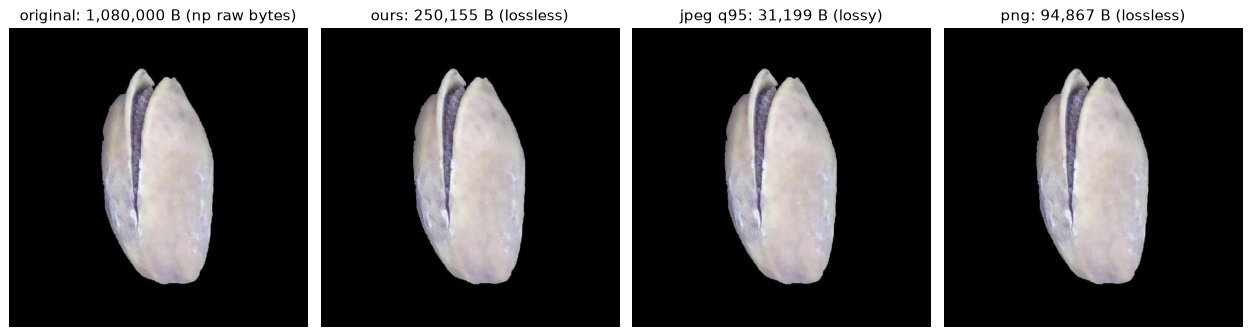

kirmizi (10).jpg
  raw:        1,080,000 bytes
  compressed:   249,258 bytes  (4.33x, 5.54 bits/pixel)
    side info: 45 bytes (header 13 + table 32)
    payload:   249,213 bytes
  png baseline (lossless): 97,616 bytes
  jpg baseline, quality=95 (lossy): 32,024 bytes
  original jpg on disk: 22,099 bytes


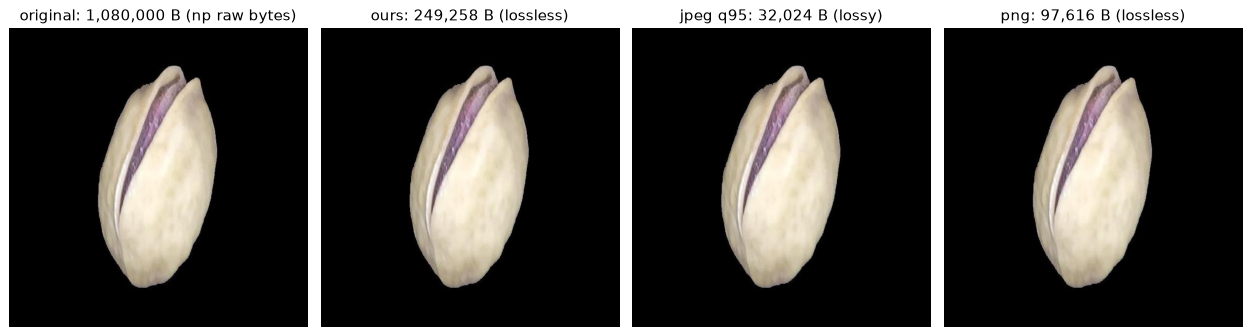

kirmizi (11).jpg
  raw:        1,080,000 bytes
  compressed:   271,690 bytes  (3.98x, 6.04 bits/pixel)
    side info: 45 bytes (header 13 + table 32)
    payload:   271,645 bytes
  png baseline (lossless): 114,154 bytes
  jpg baseline, quality=95 (lossy): 35,652 bytes
  original jpg on disk: 23,747 bytes


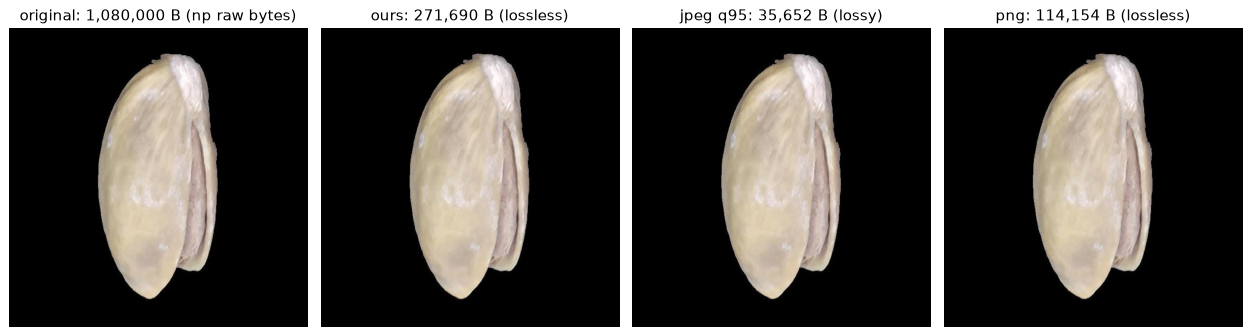

kirmizi (12).jpg
  raw:        1,080,000 bytes
  compressed:   226,125 bytes  (4.78x, 5.03 bits/pixel)
    side info: 45 bytes (header 13 + table 32)
    payload:   226,080 bytes
  png baseline (lossless): 81,907 bytes
  jpg baseline, quality=95 (lossy): 29,691 bytes
  original jpg on disk: 21,473 bytes


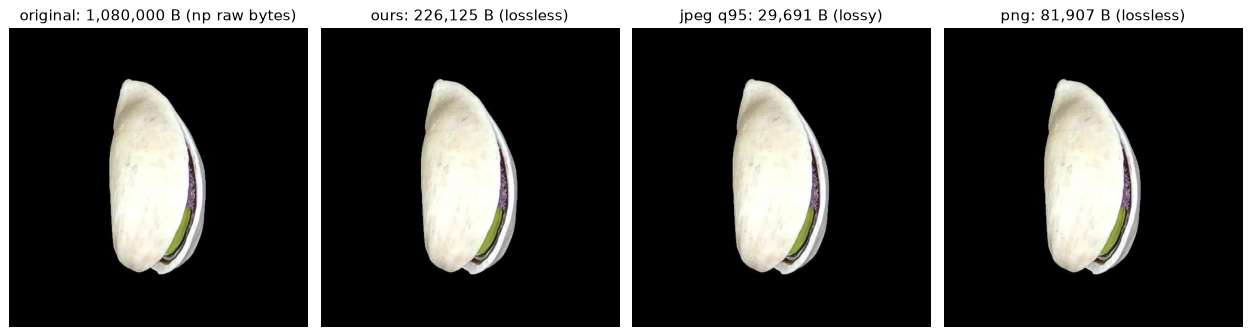

kirmizi (13).jpg
  raw:        1,080,000 bytes
  compressed:   247,775 bytes  (4.36x, 5.51 bits/pixel)
    side info: 45 bytes (header 13 + table 32)
    payload:   247,730 bytes
  png baseline (lossless): 105,618 bytes
  jpg baseline, quality=95 (lossy): 34,772 bytes
  original jpg on disk: 23,371 bytes


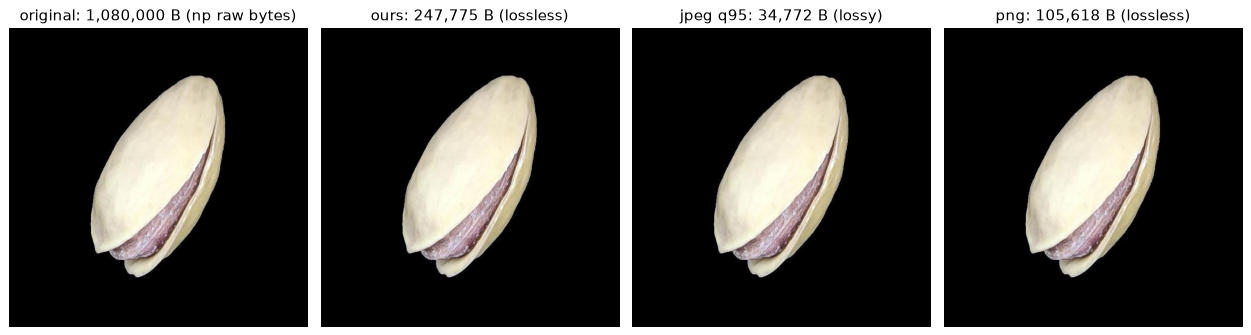

In [ ]:
from pathlib import Path
from PIL import Image
import io
import matplotlib.pyplot as plt

def load_images(folder: Path, limit=None):
    records = []
    for path in sorted(folder.rglob("*")):
        if path.suffix.lower() not in {".jpg", ".jpeg"}:
            continue
        if limit is not None and len(records) >= limit:
            break
        with Image.open(path) as im:
            arr = np.asarray(im.convert("RGB"))
        records.append({"path": path, "arr": arr})
    return records

RESOURCE_DIR_KIRMIZI = Path("dataset/Pistachio_Image_Dataset/Pistachio_Image_Dataset/Kirmizi_Pistachio")

def show_image(ax, a, title=None):
    ax.imshow(a)
    ax.set_xticks([]); ax.set_yticks([])
    if title:
        ax.set_title(title)


def jepg_bytes(arr, quality=95, subsampling=0):
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="JPEG", quality=quality, subsampling=subsampling)
    return len(buf.getvalue())

def jpeg_decoded(arr, quality):
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="JPEG", quality=quality, subsampling=0)
    return np.asarray(Image.open(buf).convert("RGB"))

def png_bytes(arr):
	buf = io.BytesIO()
	Image.fromarray(arr).save(buf, format="PNG")
	return len(buf.getvalue())

def png_decoded(arr):
    buf = io.BytesIO()
    Image.fromarray(arr).save(buf, format="PNG")
    return np.asarray(Image.open(buf).convert("RGB"))

def report(rec, compressed, recovered, header_bytes=13):
    arr = rec["arr"]
    raw = arr.nbytes
    out = len(compressed)
    table_syms = compressed[11:13]                     
    n_syms = int.from_bytes(table_syms, "big")
    side = header_bytes + 2 * n_syms                    
    payload = out - side
    bpp = out * 8 / arr.shape[0] / arr.shape[1]

    print(f"{rec['path'].name}")
    print(f"  raw:       {raw:>10,} bytes")
    print(f"  compressed:{out:>10,} bytes  ({raw/out:.2f}x, {bpp:.2f} bits/pixel)")
    print(f"    side info: {side:,} bytes (header {header_bytes} + table {2*n_syms})")
    print(f"    payload:   {payload:,} bytes")
    print(f"  png baseline (lossless): {png_bytes(arr):,} bytes")
    print(f"  jpg baseline, quality=95 (lossy): {jepg_bytes(arr):,} bytes")
    print(f"  original jpg on disk: {rec['path'].stat().st_size:,} bytes")
    
    fig, axes = plt.subplots(1, 4, figsize=(14, 4), dpi=90)
    show_image(axes[0], arr,       f"original: {raw:,} B (np raw bytes)")
    show_image(axes[1], recovered, f"ours: {out:,} B (lossless)")
    show_image(axes[2], png_decoded(arr), f"png: {png_bytes(arr):,} B (lossless)")
    show_image(axes[3], jpeg_decoded(arr, 95), f"jpeg q95: {jepg_bytes(arr, 95):,} B (lossy)")
    fig.tight_layout()
    plt.show()
    
# Example: unseen test
unseen = load_images(Path(RESOURCE_DIR_KIRMIZI), limit=5)
for rec in unseen:
    compressed = compress(rec["arr"])
    recovered = decompress(compressed)
    assert np.array_equal(recovered, rec["arr"])
    report(rec, compressed, recovered)